In [1]:
import torch
import torch.nn as nn
import torchvision.transforms.functional as FT
import torch.nn.functional as F
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import csv
import random
import math
import json
import pandas as pd

from PIL import Image
from pathlib import Path
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.models.segmentation.fcn import FCNHead
from use_croma import PretrainedCROMA

In [2]:
from helper import load_split_paths, load_image_pair, prepare_sample, CROMAFloodSegmentation, Sen1Floods11Dataset
from helper import IGNORE_INDEX, CROP_SIZE

#### **First things first**


In [3]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

pretrained_path = "pretrained/CROMA_large.pt"

path_to_the_dataset = "dataset/sen1floods11_hand_labeled_only/HandLabeled/"

path_to_the_dataset_index = "dataset/sen1floods11_hand_labeled_only/flood_handlabeled/"

path_to_X = path_to_the_dataset + "S1Hand/"

path_to_Y = path_to_the_dataset + "LabelHand/"

path_to_permanent_water = path_to_the_dataset + "JRCWaterHand"

path_to_test_csv = path_to_the_dataset_index + "flood_test_data.csv"
path_to_test_bolivia_csv = path_to_the_dataset_index + "flood_bolivia_data.csv"

print(device)

cuda


#### **Functions**

In [4]:
## Note here mIoU is not being computed!
def preprocess_test(data):
   
    return prepare_sample(data)

#### **Creating datasets**

In [5]:
test_data_non_bolivia = load_split_paths(path_to_test_csv, path_to_X, path_to_Y)
test_data_bolivia = load_split_paths(path_to_test_bolivia_csv, path_to_X, path_to_Y)

In [6]:
print(f"Non bolivia test samples: {len(test_data_non_bolivia)}")
print(f"Bolivia test samples: {len(test_data_bolivia)}")

Non bolivia test samples: 90
Bolivia test samples: 15


In [7]:
print(test_data_non_bolivia[0])
print(test_data_bolivia[0])

(WindowsPath('dataset/sen1floods11_hand_labeled_only/HandLabeled/S1Hand/Ghana_313799_S1Hand.tif'), WindowsPath('dataset/sen1floods11_hand_labeled_only/HandLabeled/LabelHand/Ghana_313799_LabelHand.tif'))
(WindowsPath('dataset/sen1floods11_hand_labeled_only/HandLabeled/S1Hand/Bolivia_103757_S1Hand.tif'), WindowsPath('dataset/sen1floods11_hand_labeled_only/HandLabeled/LabelHand/Bolivia_103757_LabelHand.tif'))


In [8]:
test_dataset_non_bolivia = Sen1Floods11Dataset(
 data_list = test_data_non_bolivia,
 preprocess_func=preprocess_test
)

test_dataset_bolivia = Sen1Floods11Dataset(
 data_list = test_data_bolivia,
 preprocess_func=preprocess_test
)

In [9]:
test_loader_non_bolivia = DataLoader(
    test_dataset_non_bolivia,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader_bolivia = DataLoader(
    test_dataset_bolivia,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

#### **Model**

In [10]:
croma = PretrainedCROMA(pretrained_path= pretrained_path, 
                        size='large', 
                        modality='SAR', 
                        image_resolution=120)

croma = croma.to(device)

Initializing SAR encoder


In [11]:
croma.requires_grad_(False) # Freeze the weights of CROMA
croma.eval()

PretrainedCROMA(
  (s1_encoder): ViT(
    (linear_input): Linear(in_features=128, out_features=1024, bias=True)
    (transformer): BaseTransformer(
      (layers): ModuleList(
        (0-11): 12 x ModuleList(
          (0): Attention(
            (to_qkv): Linear(in_features=1024, out_features=3072, bias=False)
            (to_out): Linear(in_features=1024, out_features=1024, bias=True)
            (input_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
            (dropout): Dropout(p=0.0, inplace=False)
          )
          (1): FFN(
            (net): Sequential(
              (0): Linear(in_features=1024, out_features=4096, bias=True)
              (1): GELU(approximate='none')
              (2): Dropout(p=0.0, inplace=False)
              (3): Linear(in_features=4096, out_features=1024, bias=True)
            )
            (input_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
          )
        )
      )
      (norm_out): LayerNo

#### **Creating the head**

In [12]:
head = FCNHead(in_channels=1024, channels=2)

head[1] = nn.GroupNorm(
    num_groups=16,
    num_channels=256
)

head = head.to(device)

In [13]:
checkpoint = torch.load(
    "checkpoints/croma_best_head_weighted_loss_with_scheduler.pt",
    map_location=device,
    weights_only=True
)

head.load_state_dict(checkpoint["head_state_dict"])

print("FCN weights loaded successfully!")

FCN weights loaded successfully!


In [14]:
model = CROMAFloodSegmentation(croma, head).to(device)
model.eval()

CROMAFloodSegmentation(
  (croma): PretrainedCROMA(
    (s1_encoder): ViT(
      (linear_input): Linear(in_features=128, out_features=1024, bias=True)
      (transformer): BaseTransformer(
        (layers): ModuleList(
          (0-11): 12 x ModuleList(
            (0): Attention(
              (to_qkv): Linear(in_features=1024, out_features=3072, bias=False)
              (to_out): Linear(in_features=1024, out_features=1024, bias=True)
              (input_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (1): FFN(
              (net): Sequential(
                (0): Linear(in_features=1024, out_features=4096, bias=True)
                (1): GELU(approximate='none')
                (2): Dropout(p=0.0, inplace=False)
                (3): Linear(in_features=4096, out_features=1024, bias=True)
              )
              (input_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine

In [15]:
criterion = nn.CrossEntropyLoss(
    weight=torch.tensor([1.0, 8.0], device=device),
    ignore_index=IGNORE_INDEX
)

In [16]:
@torch.inference_mode()
def sliding_window_logits(
    model,
    image,
    device,
    tile_size=120,
    stride=60,
    tile_batch_size=8
):
    """
    Predict segmentation logits for one complete image.

    Parameters
    ----------
    model:
        Frozen CROMA + trained FCN head.

    image:
        Tensor [2, H, W], already normalized.

    device:
        CUDA or CPU.

    tile_size:
        Spatial size of each CROMA input (120).

    stride:
        Distance between consecutive windows (60 = 50% overlap).

    tile_batch_size:
        Number of windows processed simultaneously.

    Returns
    -------
    logits:
        Tensor [2, H, W] on CPU.
    """

    model.eval()

    C, H, W = image.shape

    assert C == 2
    assert H >= tile_size and W >= tile_size
    assert 0 < stride <= tile_size

    # Generate starting positions along one dimension
    def get_starts(length):
        starts = list(
            range(0, length - tile_size + 1, stride)
        )

        # Ensure the final window reaches the image boundary
        if starts[-1] != length - tile_size:
            starts.append(length - tile_size)

        return starts

    # All window coordinates
    positions = [
        (top, left)
        for top in get_starts(H)
        for left in get_starts(W)
    ]

    # Accumulate predictions and coverage counts
    logits_sum = torch.zeros((2, H, W), dtype=torch.float32)
    counts = torch.zeros((H, W), dtype=torch.float32)

    # Process windows in batches
    for start in range(0, len(positions), tile_batch_size):

        batch_positions = positions[start:start + tile_batch_size]

        # Extract tiles
        tiles = torch.stack([
            image[:, top:top + tile_size, left:left + tile_size]
            for top, left in batch_positions
        ])

        tiles = tiles.to(device)

        # Run frozen CROMA + FCN head
        outputs = model(tiles).cpu()

        # Place tile predictions back into the full image
        for (top, left), logits in zip(batch_positions, outputs):

            logits_sum[
                :, top:top + tile_size, left:left + tile_size
            ] += logits

            counts[
                top:top + tile_size, left:left + tile_size
            ] += 1

    assert (counts > 0).all(), "Some pixels were not covered."

    # Average logits wherever windows overlap
    return logits_sum / counts.unsqueeze(0)

@torch.inference_mode()
def test(
    model,
    valid_loader,
    criterion,
    device,
    save_predictions=False,
    save_dir="results/croma_test",
    test_data=None,
    save_metrics=True
):
    model.eval()

    if criterion.reduction != "mean":
        raise ValueError("This implementation expects reduction='mean'.")

    save_dir = Path(save_dir)

    if save_predictions:
        if test_data is None:
            raise ValueError("Provide test_data to save georeferenced predictions.")

        if not hasattr(valid_loader.dataset, "data_list"):
            raise ValueError("Expected a dataset with data_list.")

        if list(test_data) != list(valid_loader.dataset.data_list):
            raise ValueError("test_data must match the dataset order.")

        if valid_loader.batch_size != 1:
            raise ValueError("Use batch_size=1 to save predictions.")

        if not isinstance(
            valid_loader.sampler,
            torch.utils.data.SequentialSampler
        ):
            raise ValueError("Use shuffle=False when saving predictions.")

    if save_predictions or save_metrics:
        save_dir.mkdir(parents=True, exist_ok=True)

    total_loss = 0.0
    total_weight = 0.0

    TP = FP = FN = TN = 0
    sample_idx = 0

    for images, masks in valid_loader:

        for image, mask in zip(images, masks):

            mask = mask.cpu().long()
            valid = mask != IGNORE_INDEX
            n_valid = valid.sum().item()

            # Full-image sliding-window inference
            logits = sliding_window_logits(
                model,
                image,
                device,
                tile_size=CROP_SIZE,
                stride=CROP_SIZE // 2,
                tile_batch_size=8
            )

            prediction = logits.argmax(dim=0)

            # Save georeferenced prediction
            if save_predictions:

                x_path, y_path = test_data[sample_idx]
                x_path = Path(x_path)

                output_path = (
                    save_dir / f"{x_path.stem}_prediction.tif"
                )

                with rasterio.open(x_path) as src:
                    profile = src.profile.copy()

                profile.update(
                    driver="GTiff",
                    count=1,
                    dtype="uint8",
                    nodata=None
                )

                pred_np = prediction.numpy().astype(np.uint8)

                with rasterio.open(output_path, "w", **profile) as dst:
                    dst.write(pred_np, 1)

            sample_idx += 1

            # Ignore samples without any valid ground-truth pixels
            if n_valid == 0:
                continue

            # Compute loss on the criterion's device
            logits_device = logits.unsqueeze(0).to(device)
            mask_device = mask.unsqueeze(0).to(device)

            loss = criterion(logits_device, mask_device)

            # Correct aggregation for weighted/unweighted CE
            if criterion.weight is not None:
                image_weight = criterion.weight[
                    mask_device[mask_device != IGNORE_INDEX]
                ].sum().item()
            else:
                image_weight = n_valid

            total_loss += loss.item() * image_weight
            total_weight += image_weight

            # Confusion matrix for the water class
            TP += (
                (prediction == 1) & (mask == 1) & valid
            ).sum().item()

            FP += (
                (prediction == 1) & (mask == 0) & valid
            ).sum().item()

            FN += (
                (prediction == 0) & (mask == 1) & valid
            ).sum().item()

            TN += (
                (prediction == 0) & (mask == 0) & valid
            ).sum().item()

    if total_weight == 0:
        raise RuntimeError("No valid test pixels.")

    def safe_div(numerator, denominator):
        return (
            numerator / denominator
            if denominator > 0
            else float("nan")
        )

    # Segmentation metrics (global / pooled)
    water_iou = safe_div(TP, TP + FP + FN)
    nonwater_iou = safe_div(TN, TN + FP + FN)
    miou = (water_iou + nonwater_iou) / 2

    # Classification metrics for water
    precision = safe_div(TP, TP + FP)
    recall = safe_div(TP, TP + FN)
    f1 = safe_div(2 * TP, 2 * TP + FP + FN)

    # Remote sensing error rates
    omission = safe_div(FN, TP + FN)
    commission = safe_div(FP, TP + FP)

    accuracy = safe_div(TP + TN, TP + TN + FP + FN)

    metrics = {
        "test_loss": total_loss / total_weight,
        "water_iou": water_iou,
        "nonwater_iou": nonwater_iou,
        "miou": miou,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "omission_error": omission,
        "commission_error": commission,
        "accuracy": accuracy,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "TN": TN,
    }

    if save_metrics:
        # Use null for undefined metrics in standards-compliant JSON
        json_metrics = {
            k: (
                None
                if isinstance(v, float) and not math.isfinite(v)
                else v
            )
            for k, v in metrics.items()
        }

        with open(save_dir / "metrics.json", "w") as f:
            json.dump(json_metrics, f, indent=4)

    return metrics

In [17]:
metrics_nonbolivia = test(
    model=model,
    valid_loader=test_loader_non_bolivia,
    criterion=criterion,
    device=device,
    save_predictions=True,
    save_dir="results/croma_test_non_bol",
    test_data=test_data_non_bolivia
)

print("Non Bolivia test: ",metrics_nonbolivia)

Non Bolivia test:  {'test_loss': 0.2843525298792197, 'water_iou': 0.6478260801338231, 'nonwater_iou': 0.9391904992965449, 'miou': 0.793508289715184, 'precision': 0.7689601130102196, 'recall': 0.8043974107020729, 'f1': 0.786279678351992, 'omission_error': 0.1956025892979271, 'commission_error': 0.23103988698978042, 'accuracy': 0.9453082844402013, 'TP': 2064165, 'FP': 620194, 'FN': 501936, 'TN': 17331072}


In [18]:
metrics_bolivia = test(
    model=model,
    valid_loader=test_loader_bolivia,
    criterion=criterion,
    device=device,
    save_predictions=True,
    save_dir="results/croma_test_bol",
    test_data=test_data_bolivia
)

print("Bolivia test: ", metrics_bolivia)

Bolivia test:  {'test_loss': 0.24391548555279882, 'water_iou': 0.6002882540168595, 'nonwater_iou': 0.8896332694054052, 'miou': 0.7449607617111323, 'precision': 0.6450246855577227, 'recall': 0.8964283829892011, 'f1': 0.7502251578865057, 'omission_error': 0.10357161701079884, 'commission_error': 0.35497531444227726, 'accuracy': 0.9053254829896629, 'TP': 407753, 'FP': 224398, 'FN': 47111, 'TN': 2188553}


In [19]:
def aw_pw_fw_targets(
    path_to_labels,
    path_to_predictions,
    path_to_permanent_water,
):
    labels_dir = Path(path_to_labels)
    predictions_dir = Path(path_to_predictions)
    permanent_dir = Path(path_to_permanent_water)

    suffix = "_S1Hand_prediction.tif"
    prediction_files = sorted(predictions_dir.glob(f"*{suffix}"))

    if not prediction_files:
        raise FileNotFoundError(
            f"No prediction files found in {predictions_dir}"
        )

    for prediction_path in prediction_files:
        chip_id = prediction_path.name.removesuffix(suffix)

        label_path = labels_dir / f"{chip_id}_LabelHand.tif"
        permanent_path = permanent_dir / f"{chip_id}_JRCWaterHand.tif"

        for path in (label_path, permanent_path):
            if not path.is_file():
                raise FileNotFoundError(path)

        with (
            rasterio.open(prediction_path) as pred_src,
            rasterio.open(label_path) as label_src,
            rasterio.open(permanent_path) as perm_src,
        ):
            # Allow tiny floating-point differences in georeferencing.
            for src in (pred_src, perm_src):
                if (
                    src.shape != label_src.shape
                    or src.crs != label_src.crs
                    or not src.transform.almost_equals(
                        label_src.transform, precision=1e-10
                    )
                ):
                    raise ValueError(f"Raster grid mismatch: {chip_id}")

            prediction = pred_src.read(1)
            y = label_src.read(1).astype(np.int16)
            p = perm_src.read(1)

        y[y == -1] = 255

        if not np.isin(prediction, [0, 1]).all():
            raise ValueError(f"Non-binary prediction: {chip_id}")
        if not np.isin(y, [0, 1, 255]).all():
            raise ValueError(f"Unexpected hand labels: {chip_id}")
        if not np.isin(p, [0, 1]).all():
            raise ValueError(f"Unexpected JRC values: {chip_id}")

        targets = {
            "AW": y.copy(),
            "PW": y.copy(),
            "FW": y.copy(),
        }

        targets["PW"][(y == 1) & (p == 0)] = 255
        targets["FW"][(y == 1) & (p == 1)] = 255

        # Historical rule: exclude chips whose water positives
        # disappear after category masking. Retain originally dry chips.
        originally_has_water = np.any(y == 1)
        included = {
            category: not (
                category != "AW"
                and originally_has_water
                and not np.any(target == 1)
            )
            for category, target in targets.items()
        }

        yield {
            "chip_id": chip_id,
            "prediction": prediction,
            "targets": targets,
            "included": included,
        }

In [20]:
hand_dir = Path(
    "dataset/sen1floods11_hand_labeled_only/HandLabeled"
)

rows = []

for split in ("non_bol", "bol"):
    records = aw_pw_fw_targets(
        path_to_labels=hand_dir / "LabelHand",
        path_to_predictions=Path("results") / f"croma_test_{split}",
        path_to_permanent_water=hand_dir / "JRCWaterHand",
    )

    for record in records:
        prediction = record["prediction"]

        for category, target in record["targets"].items():
            if not record["included"][category]:
                continue

            valid = target != 255

            tp = np.count_nonzero(valid & (prediction == 1) & (target == 1))
            fp = np.count_nonzero(valid & (prediction == 1) & (target == 0))
            fn = np.count_nonzero(valid & (prediction == 0) & (target == 1))
            tn = np.count_nonzero(valid & (prediction == 0) & (target == 0))

            rows.append({
                "split": split,
                "category": category,
                "chip_id": record["chip_id"],
                "tp": tp,
                "fp": fp,
                "fn": fn,
                "tn": tn,
                "chip_iou": (tp + 1e-7) / (tp + fp + fn + 1e-7),
            })

per_chip = pd.DataFrame(rows)

summary = (
    per_chip.groupby(["split", "category"], sort=False)
    .agg(
        evaluated_chips=("chip_id", "size"),
        mean_chip_iou=("chip_iou", "mean"),
        tp=("tp", "sum"),
        fp=("fp", "sum"),
        fn=("fn", "sum"),
        tn=("tn", "sum"),
    )
    .reset_index()
)

union = summary["tp"] + summary["fp"] + summary["fn"]
summary["total_iou"] = summary["tp"] / union.replace(0, np.nan)

display(summary[
    ["split", "category", "evaluated_chips", "mean_chip_iou", "total_iou"]
])

per_chip.to_csv("results/croma_aw_pw_fw_per_chip.csv", index=False)
summary.to_csv("results/croma_aw_pw_fw_summary.csv", index=False)

,split,category,evaluated_chips,mean_chip_iou,total_iou
0,non_bol,AW,90,0.407593,0.647826
1,non_bol,FW,90,0.329735,0.510876
2,non_bol,PW,54,0.422809,0.669184
3,bol,AW,15,0.425069,0.600288
4,bol,FW,15,0.359168,0.582554
5,bol,PW,7,0.292937,0.211407


In [21]:
from IPython.display import display, Markdown

for split, title in [
    ("non_bol", "Table 1. Non-Bolivia test set"),
    ("bol", "Table 2. Bolivia test set"),
]:
    scores = (
        summary.loc[summary["split"].eq(split)]
        .set_index("category")["mean_chip_iou"]
        .reindex(["PW", "FW", "AW"])
    )

    table = pd.DataFrame(
        [scores.to_numpy()],
        columns=["PW", "FW", "AW"],
        index=["CROMA + FCN head"],
    )
    table.index.name = "Model"

    display(Markdown(f"**{title} — Mean water IoU**"))
    display(table.style.format("{:.4f}"))

**Table 1. Non-Bolivia test set — Mean water IoU**

,PW,FW,AW
Model,,,
CROMA + FCN head,0.4228,0.3297,0.4076


**Table 2. Bolivia test set — Mean water IoU**

,PW,FW,AW
Model,,,
CROMA + FCN head,0.2929,0.3592,0.4251


In [24]:
from sen1floods11_visualization import plot_predictions

fig, axes, chip_ids = plot_predictions(
    predictions_dir="results/croma_test_non_bol",
    hand_dir="dataset/sen1floods11_hand_labeled_only/HandLabeled",
    n=90,
    seed=42,
    save_path="results/croma_visualization.png",
    show_errors=True
)

plt.show()

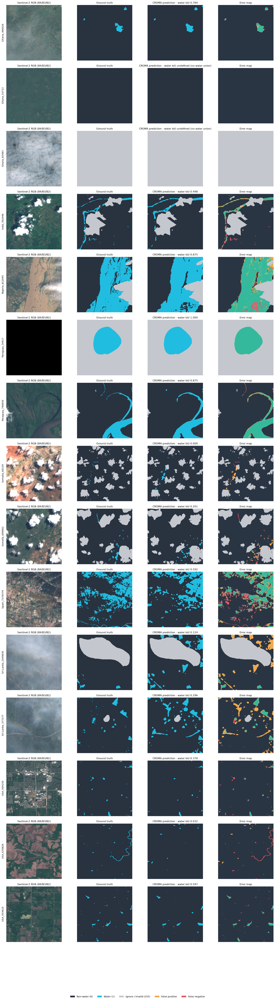

In [25]:

fig, axes, chip_ids = plot_predictions(
    predictions_dir="results/croma_test_non_bol",
    hand_dir="dataset/sen1floods11_hand_labeled_only/HandLabeled",
    n=15,
    seed=42,
    save_path="results/croma_visualization.png",
    show_errors=True
)

plt.show()